# Lesson 3 · Forecast Evaluation: Metrics, Baselines & Walk-Forward Validation
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 14** &nbsp;|&nbsp; ⏱ ≈ 105 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Compute and interpret **MAE, RMSE, MAPE** (and sMAPE, MASE), and know when MAPE is dangerous
> - Build and use **baseline forecasts** (naive, seasonal naive, drift, mean)
> - Explain why **shuffling destroys time-series evaluation** and demonstrate it
> - Implement **walk-forward (rolling-origin) validation**
> - Evaluate across **forecast horizons**

**Prerequisites:** Lessons 0–2.

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 1 · How do you grade a forecast?

A forecast is a *prediction about the future*, so you can't grade it today: you have to wait. To avoid waiting we **pretend**: hide the most recent data (the **test set**),
forecast it from the older data (the **training set**), and compare.

The **forecast error** at time $t$ is  $e_t = y_t - \hat y_t$  (actual minus forecast). Positive = we under-forecast; negative = we over-forecast.

One number per forecast is needed to compare models. Different summaries answer different questions.

## 2 · The metrics

| Metric | Formula | Units | Behaviour |
|---|---|---|---|
| **MAE** (Mean Absolute Error) | $\frac1n\sum \lvert e_t \rvert$ | same as $y$ | "On average we're off by X kg-prices." Robust, easy to explain |
| **RMSE** (Root Mean Squared Error) | $\sqrt{\frac1n\sum e_t^2}$ | same as $y$ | **Punishes large errors** more. Always ≥ MAE |
| **MAPE** (Mean Absolute % Error) | $\frac{100}{n}\sum \left\lvert \frac{e_t}{y_t}\right\rvert$ | % | Scale-free, but **breaks at/near zero** and is asymmetric |
| **sMAPE** | $\frac{100}{n}\sum \frac{2\lvert e_t\rvert}{\lvert y_t\rvert+\lvert\hat y_t\rvert}$ | % | Symmetric-ish fix; defined unless both are 0 |
| **MASE** | $\frac{\text{MAE}}{\text{MAE of in-sample naive}}$ | ratio | < 1 means better than naive; works across series and zeros |

> 💡 **Which should I report?** Use **MAE** as the headline (everyone understands it), **RMSE** if big misses are especially costly (a farmer who sells at a 40 % loss is far worse off than two who lose 20 %),
> and **MASE** or a baseline ratio when comparing across commodities. Use MAPE only if the series stays *far from zero*.

Let's write them ourselves: you only truly understand a metric after you've coded it.

In [2]:
def my_mae(y, yhat):  return np.mean(np.abs(np.asarray(y) - np.asarray(yhat)))
def my_rmse(y, yhat): return np.sqrt(np.mean((np.asarray(y) - np.asarray(yhat)) ** 2))
def my_mape(y, yhat): return 100 * np.mean(np.abs((np.asarray(y) - np.asarray(yhat)) / np.asarray(y)))

y    = np.array([100., 120., 80., 90.])
yhat = np.array([ 95., 130., 70., 90.])
print(f"MAE  = {my_mae(y, yhat):.2f}")
print(f"RMSE = {my_rmse(y, yhat):.2f}   (bigger than MAE because of the 10-unit misses)")
print(f"MAPE = {my_mape(y, yhat):.2f}%")

MAE  = 6.25
RMSE = 7.50   (bigger than MAE because of the 10-unit misses)
MAPE = 6.46%


### ⚠️ The two faces of MAPE trouble

**1. Zero / near-zero actuals.** Percentage error divides by the actual; dividing by 0 is undefined and by 0.1 is astronomical.

In [3]:
print("Actual = 0.1, forecast = 5   ->", f"{abs(0.1 - 5) / 0.1 * 100:.0f}% error!")
print("Actual = 0,   forecast = 5   ->", f"{mape([0, 100], [5, 100])}  (course_utils.mape returns NaN on purpose, instead of a silent inf)")

Actual = 0.1, forecast = 5   -> 4900% error!
Actual = 0,   forecast = 5   -> nan  (course_utils.mape returns NaN on purpose, instead of a silent inf)


**2. Asymmetry.** An under-forecast can never score worse than 100 %, but an over-forecast has no ceiling. Same absolute miss of 50, swap the roles of actual and forecast:

In [4]:
for actual, fc, kind in [(100, 150, "over-forecast"), (150, 100, "under-forecast"), (50, 500, "over-forecast (big)")]:
    print(f"actual={actual:>3}, forecast={fc:>3}  {kind:<20} ->  MAPE = {abs(actual-fc)/actual*100:.0f}%")
print("Same size of miss (50) scores 50% vs 33%; and over-forecasts can reach 900% while under-forecasts are capped at 100%.")

actual=100, forecast=150  over-forecast        ->  MAPE = 50%
actual=150, forecast=100  under-forecast       ->  MAPE = 33%
actual= 50, forecast=500  over-forecast (big)  ->  MAPE = 900%
Same size of miss (50) scores 50% vs 33%; and over-forecasts can reach 900% while under-forecasts are capped at 100%.


So: **MAPE favours models that under-forecast.** Fine for a report to a manager who loves percentages: dangerous for model *selection*.

## 3 · Baselines: the bar every model must clear

> *"A model is only as good as the simplest thing it beats."*

| Baseline | Rule | When it's hard to beat |
|---|---|---|
| **Naive** | $\hat y_{t+h} = y_t$ | Random-walk-like series (prices!) at short horizons |
| **Seasonal naive** | $\hat y_{t+h} = y_{t+h-m}$ | Strongly seasonal series |
| **Mean** | $\hat y_{t+h} = \bar y$ | Stationary noise around a fixed level |
| **Drift** | extend the line from first to last point | Steady trends |
| **Moving average** | mean of last *w* values | Noisy, level-shifting series |

Each is just a few lines (they're in `course_utils` as `fc_naive`, `fc_snaive`, …). Convention: a forecaster takes the **training series** and the horizon `h` and returns `h` numbers.

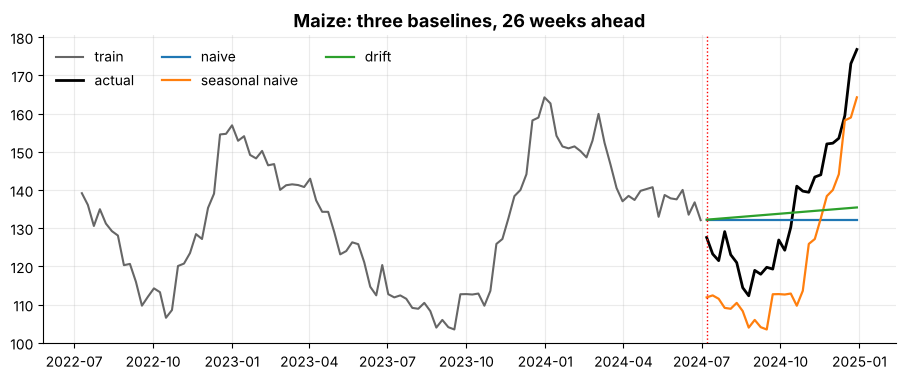

,MAE,RMSE,MAPE,sMAPE,MASE
seasonal naive,13.469,14.680,10.091,10.735,5.386
drift,13.817,16.613,10.006,10.094,5.526
naive,14.364,17.604,10.264,10.496,5.744


In [5]:
def naive(train, h):          return np.repeat(train.iloc[-1], h)
def seasonal_naive(train, h, m=52):
    last_season = train.iloc[-m:].values
    return np.resize(last_season, h)                 # repeat last year's values for the next h weeks
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

maize = load_weekly("maize")["price"]
h = 26
train, test = maize.iloc[:-h], maize.iloc[-h:]            # chronological split: train = past, test = future
fcs = {"naive": naive(train, h), "seasonal naive": seasonal_naive(train, h), "drift": drift(train, h)}
plot_forecasts(train, test, fcs, "Maize: three baselines, 26 weeks ahead"); plt.show()
score_table(test, fcs, y_train=train, m=1)

### 📐 Skill score: "how much better than naive?"

$$\text{skill} = 1 - \frac{\text{RMSE}_{\text{model}}}{\text{RMSE}_{\text{naive}}}$$

Positive → better than naive; 0 → same; negative → **worse than doing nothing clever**. We will compute this for every model we build.

## 4 · Why shuffling is poison (the experiment)

In Phase 5 you learned `train_test_split(..., shuffle=True)`. For time series, that default is **a bug waiting to happen**.
Let's prove it. We predict the maize price **12 weeks ahead** with a Random Forest, evaluated in two ways:
1. a **random** 80/20 split (what a careless pipeline does), and
2. a **chronological** 80/20 split (what reality does).
Same model, same data, same features: only the split differs.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

mz = load_weekly("maize")
h = 12
X, y = make_features(mz, lags=(12, 13, 14, 26, 52), windows=(), h=h, fourier_k=2)
X["t"] = np.arange(len(X))                                # a simple time index
d = X.join(y.rename("y")).dropna()
Xd, yd = d.drop(columns="y"), d["y"]

# (1) careless: random split
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, shuffle=True, random_state=0)
rf = RandomForestRegressor(200, random_state=0).fit(Xtr, ytr)
pred_random = rf.predict(Xte)
mae_random = mae(yte, pred_random);  naive_random = mae(yte, Xte["price_lag_12"])

# (2) honest: chronological split
k = int(len(d) * 0.8)
rf = RandomForestRegressor(200, random_state=0).fit(Xd.iloc[:k], yd.iloc[:k])
pred_chrono = rf.predict(Xd.iloc[k:])
mae_chrono = mae(yd.iloc[k:], pred_chrono);  naive_chrono = mae(yd.iloc[k:], Xd.iloc[k:]["price_lag_12"])

print(f"Random split        : RF MAE = {mae_random:5.2f}   (naive-12 on those rows: {naive_random:5.2f})   <- looks amazing!")
print(f"Chronological split : RF MAE = {mae_chrono:5.2f}   (naive-12 on those rows: {naive_chrono:5.2f})   <- the truth")
print(f"\nThe random split made the model look {mae_chrono / mae_random:.1f}x better than it really is.")

Random split        : RF MAE =  3.46   (naive-12 on those rows: 13.83)   <- looks amazing!
Chronological split : RF MAE = 17.89   (naive-12 on those rows: 19.88)   <- the truth

The random split made the model look 5.2x better than it really is.


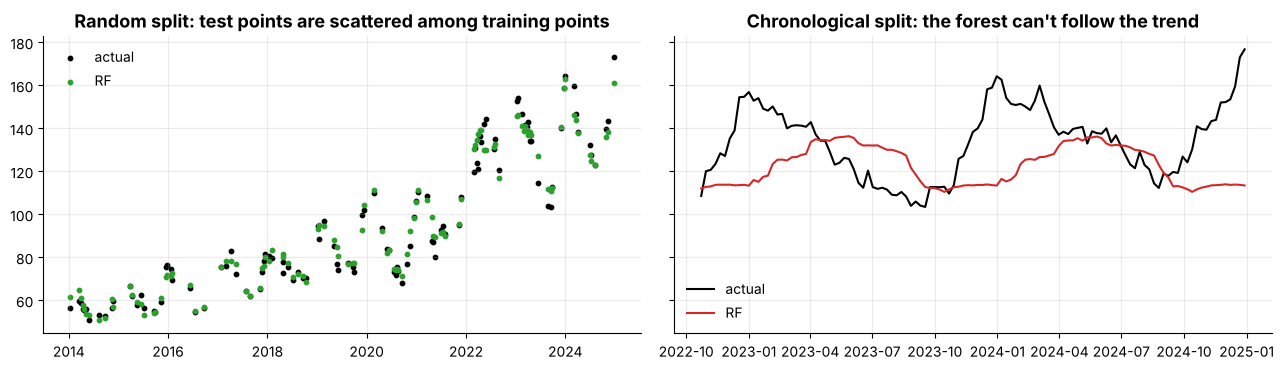

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
ax[0].scatter(yte.index, yte, s=10, c="black", label="actual"); ax[0].scatter(yte.index, pred_random, s=10, c="tab:green", label="RF")
ax[0].set_title("Random split: test points are scattered among training points"); ax[0].legend()
ax[1].plot(yd.index[k:], yd.iloc[k:], c="black", label="actual"); ax[1].plot(yd.index[k:], pred_chrono, c="tab:red", label="RF")
ax[1].set_title("Chronological split: the forest can't follow the trend"); ax[1].legend()
plt.tight_layout(); plt.show()

### 🧠 What went wrong with the shuffled split?
1. **Leakage through neighbours.** Prices at *t − 1* and *t + 1* are in the training set. With a time index or calendar features, the forest can almost *look up* the answer.
2. **The future isn't an interpolation.** In production we must **extrapolate** beyond the training range (here prices keep rising). Random splits only ever interpolate.
3. **Hyper-parameter tuning on this score** would select models that exploit the leak.

> 🏛️ **The Rule:** training data **must precede** validation data, and validation data must precede test data. *Always.*

## 5 · Walk-forward validation (rolling-origin evaluation)

One chronological split gives **one** number from **one** slice of history. Was the test window unusually calm? Unusually wild? You can't tell.
**Walk-forward validation** repeats the experiment at many forecast origins:

```
fold 1:  [train ████████████]  [test ▒▒▒]
fold 2:  [train ██████████████]  [test ▒▒▒]
fold 3:  [train ████████████████]  [test ▒▒▒]
```

At each **origin** we (1) train on everything up to the origin, (2) forecast the next *h* steps, (3) record the errors, then (4) roll the origin forward.
- **Expanding window**: training set grows (more data; good when old data stays relevant).
- **Sliding window**: fixed length (adapts if the market *changes regime*).

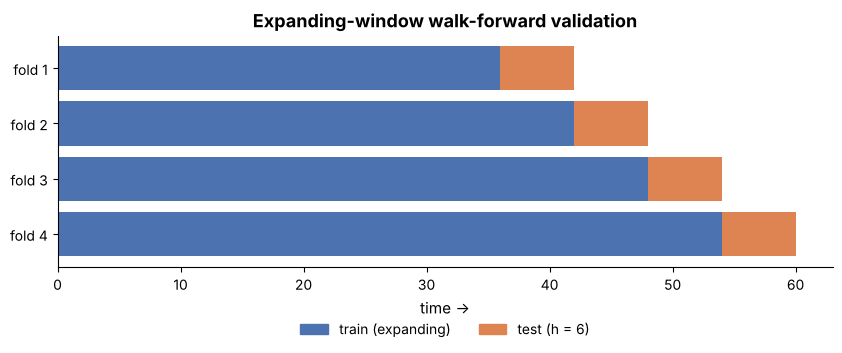

In [8]:
# A picture of the folds
import matplotlib.patches as mpatches
n, initial, hz, step = 60, 36, 6, 6
fig, ax = plt.subplots(figsize=(10, 3))
for i, origin in enumerate(range(initial, n - hz + 1, step)):
    ax.barh(i, origin, color="#4C72B0"); ax.barh(i, hz, left=origin, color="#DD8452")
ax.set_yticks(range(len(range(initial, n - hz + 1, step)))); ax.set_yticklabels([f"fold {i+1}" for i in range(len(range(initial, n - hz + 1, step)))])
ax.invert_yaxis(); ax.set_xlabel("time →"); ax.grid(False)
ax.legend(handles=[mpatches.Patch(color="#4C72B0", label="train (expanding)"), mpatches.Patch(color="#DD8452", label="test (h = 6)")], loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.set_title("Expanding-window walk-forward validation"); plt.show()

Our `walk_forward` helper takes **any forecaster** `f(train, h)` and returns a tidy table. Let's compare three baselines on maize for a 12-week horizon, with 150 origins:

In [9]:
s = load_weekly("maize")["price"]
initial, H = 470, 12
results = {}
for name, f in {"naive": fc_naive, "drift": fc_drift, "moving avg (8)": fc_ma, "seasonal naive": fc_snaive}.items():
    results[name] = walk_forward(s, f, initial=initial, horizon=H, step=1)

wf = results["naive"]
print("Each row = one forecast of one future week made from one origin:")
wf.head(4)

Each row = one forecast of one future week made from one origin:


,origin,target_date,h,actual,forecast
0,2022-01-02,2022-01-09,1,111.12,109.71
1,2022-01-02,2022-01-16,2,112.62,109.71
2,2022-01-02,2022-01-23,3,119.28,109.71
3,2022-01-02,2022-01-30,4,115.46,109.71


In [10]:
summary = pd.DataFrame({name: {"MAE": mae(w.actual, w.forecast), "RMSE": rmse(w.actual, w.forecast)} for name, w in results.items()}).T
summary["skill vs naive (RMSE)"] = 1 - summary["RMSE"] / summary.loc["naive", "RMSE"]
print(f"{wf.origin.nunique()} forecast origins x {H} horizons = {len(wf)} out-of-sample forecasts per model\n")
summary.round(3).sort_values("RMSE")

145 forecast origins x 12 horizons = 1740 out-of-sample forecasts per model



,MAE,RMSE,skill vs naive (RMSE)
naive,11.738,15.289,0.000
drift,11.960,15.354,-0.004
moving avg (8),14.814,18.268,-0.195
seasonal naive,19.795,24.806,-0.622


### 5b · Scikit-learn's `TimeSeriesSplit`
If you use scikit-learn models you'll often prefer its built-in splitter. It produces *expanding-window* folds, always training on the past:

In [11]:
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5, test_size=26, gap=0)      # gap>0 leaves a buffer between train and test
for i, (tr, te) in enumerate(tscv.split(s)):
    print(f"fold {i+1}: train weeks 0..{tr[-1]:>3}  ->  test weeks {te[0]}..{te[-1]}   (train always before test: {tr.max() < te.min()})")

fold 1: train weeks 0..495  ->  test weeks 496..521   (train always before test: True)
fold 2: train weeks 0..521  ->  test weeks 522..547   (train always before test: True)
fold 3: train weeks 0..547  ->  test weeks 548..573   (train always before test: True)
fold 4: train weeks 0..573  ->  test weeks 574..599   (train always before test: True)
fold 5: train weeks 0..599  ->  test weeks 600..625   (train always before test: True)


> 💡 **`gap`:** if you forecast *h* steps ahead using features up to the origin, set `gap = h − 1` so the training targets don't overlap the test period.

## 6 · Forecast horizons: error grows with the distance

Forecasting next week is easier than next quarter. Always report **error by horizon**: a model may be great at *h* = 1 and useless at *h* = 12.

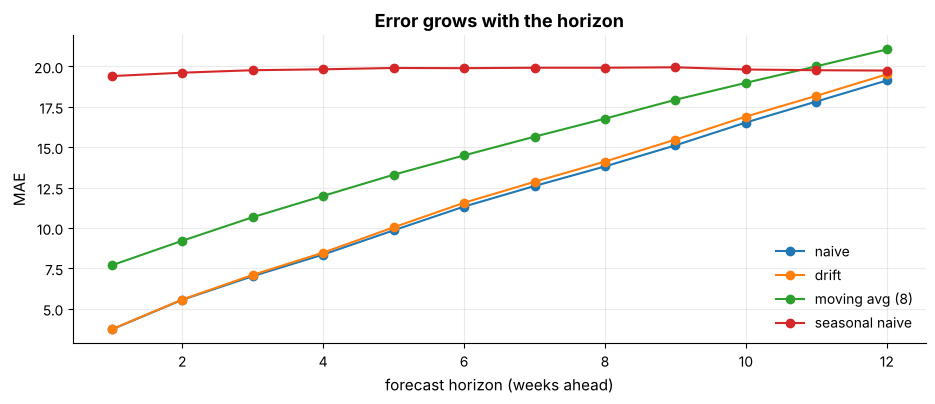

In [12]:
fig, ax = plt.subplots()
for name, w in results.items():
    bh = scores_by_horizon(w)
    ax.plot(bh.index, bh["MAE"], marker="o", label=name)
ax.set_xlabel("forecast horizon (weeks ahead)"); ax.set_ylabel("MAE"); ax.set_title("Error grows with the horizon"); ax.legend(); plt.show()

Two observations to remember:
- **The naive forecast is excellent at h = 1** (MAE ≈ 3.7) (most of next week *is* this week) but its error grows roughly linearly with the horizon, reaching ≈ 19 by h = 12.
- **Seasonal naive** has a *flat* error profile (≈ 19–20 at every horizon): it is bad at h = 1 but doesn't deteriorate. By h ≈ 12 the two have met, so beyond roughly one quarter ahead the seasonal baseline becomes the one to beat. (Its constant error comes from the year-on-year trend it ignores.)

### Multi-step strategies (preview)
| Strategy | Idea | Pro / Con |
|---|---|---|
| **Recursive** | Predict 1 step, feed it back as an input, repeat | one model; errors compound |
| **Direct** | Train a separate model for each horizon *h* | no feedback loop; many models |
| **Multi-output** | One model outputs all *h* values | compact; needs models that support it |

## 7 · Residual diagnostics (is there signal left behind?)

A good model leaves residuals that look like **white noise**: mean ≈ 0, no autocorrelation. Leftover autocorrelation means the model missed structure.

Mean error (bias) of the naive h=1 forecast: 0.14   (≈0 would be unbiased)


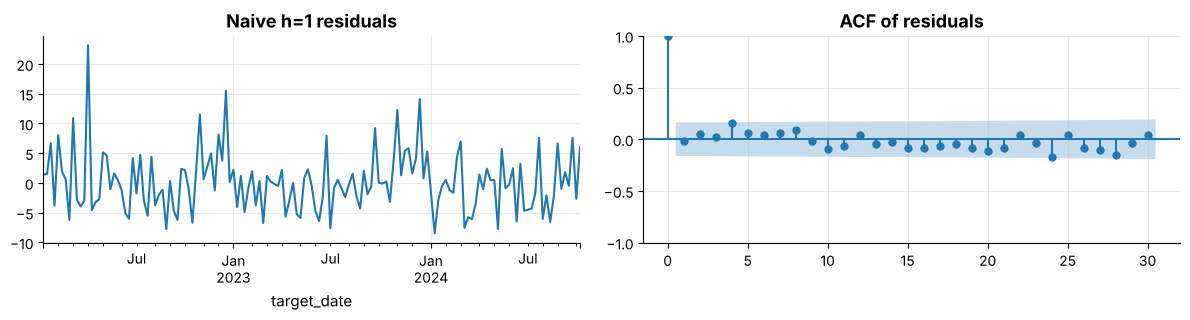

In [13]:
from statsmodels.graphics.tsaplots import plot_acf
e = wf[wf.h == 1].set_index("target_date")
resid = (e.actual - e.forecast)
print(f"Mean error (bias) of the naive h=1 forecast: {resid.mean():.2f}   (≈0 would be unbiased)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
resid.plot(ax=ax[0], title="Naive h=1 residuals"); plot_acf(resid, lags=30, ax=ax[1], title="ACF of residuals")
plt.tight_layout(); plt.show()

## 8 · The evaluation protocol (print this out!)

1. **Split chronologically.** Never shuffle. Train < validation < test.
2. **Choose the horizon(s)** that match the real decision (a trader buying 8 weeks ahead cares about h = 8, not h = 1).
3. **Always include baselines**: naive and seasonal naive at minimum.
4. **Use walk-forward / rolling-origin** with as many origins as practical; report mean *and* spread.
5. **Report several metrics** (MAE + RMSE; MASE/skill for cross-series; MAPE only away from zero).
6. **Break results down by horizon** (and, when relevant, by season or by regime; e.g., drought vs normal years).
7. **Fit every scaler / imputer / feature selector on training data only.**
8. **Touch the final test set once.** Tune on validation; report on test.

## 🧩 Practice problems

### 🧩 Problem 3.1 · Metrics by hand  ·  🟢 Easy

Actual prices: `[100, 110, 120, 130]`. Forecasts: `[98, 115, 118, 140]`.
  Compute **MAE**, **RMSE** and **MAPE** using only NumPy (no helper functions). Store the MAE in `my_mae`.

<details><summary>💡 Hint 1</summary>

Errors are `y - yhat` = `[2, -5, 2, -10]`.

</details>

<details><summary>💡 Hint 2</summary>

MAE = mean of `abs(errors)`. RMSE = `sqrt(mean(errors**2))`.

</details>

<details><summary>💡 Hint 3</summary>

MAPE = `100 * mean(abs(errors / y))`.

</details>

In [14]:
y    = np.array([100, 110, 120, 130])
yhat = np.array([98, 115, 118, 140])
my_mae = None
# YOUR CODE HERE
check('MAE', my_mae, 4.75)

⏳ MAE: not answered yet (replace the `None` with your answer)


### 🧩 Problem 3.2 · The MAPE trap  ·  🟡 Medium

The raw daily file has a `rainfall_mm` column where **82 %** of days are *exactly* zero. Take the last 60 values of daily rainfall as `actual`
  and forecast them with the average of the *previous* 60 days (a flat forecast).
  (a) Compute MAPE with `course_utils.mape`: what happens? (b) Compute MAE and sMAPE instead. (c) In a comment, explain why MAPE fails and
  name two situations in *agricultural* forecasting where this could bite.

<details><summary>💡 Hint 1</summary>

`rain = pd.read_csv(DATA/'maize_daily_raw.csv')['rainfall_mm'].values` then `actual = rain[-60:]`, `fc = np.full(60, rain[-120:-60].mean())`.

</details>

<details><summary>💡 Hint 2</summary>

MAPE divides by the actual value. What is `error / 0`?

</details>

<details><summary>💡 Hint 3</summary>

Think: arrivals on a market-closed day, rainfall in the dry season, a commodity with prices that can fall near zero (glut).

</details>

In [15]:
rain = pd.read_csv(DATA / 'maize_daily_raw.csv')['rainfall_mm'].values
# YOUR CODE HERE

### 🧩 Problem 3.3 · Which baseline wins for onion?  ·  🟡 Medium

Hold out the last **52 weeks** of **onion** prices. Using the functions `fc_naive`, `fc_mean`, `fc_drift`, `fc_snaive`, forecast all 52 weeks from the end of the training data
  and print a `score_table`. Which baseline wins and why? Then create the plot with `plot_forecasts`.

<details><summary>💡 Hint 1</summary>

`s = load_weekly('onion')['price']; train, test = s.iloc[:-52], s.iloc[-52:]`

</details>

<details><summary>💡 Hint 2</summary>

Each baseline: `fc_naive(train, 52)`. Collect into a dict `{'naive': ..., 'snaive': ...}`.

</details>

<details><summary>💡 Hint 3</summary>

`score_table(test, forecasts, y_train=train, m=52)` ranks them.

</details>

In [16]:
s = load_weekly('onion')['price']
train, test = s.iloc[:-52], s.iloc[-52:]
# YOUR CODE HERE

### 🧩 Problem 3.4 · Walk-forward for rice  ·  🟡 Medium

Run a walk-forward evaluation on **rice** with `walk_forward(..., initial=400, horizon=4, step=4)` for `fc_naive` and `fc_drift`.
  Report the overall MAE for each and the MAE **by horizon** (1–4 weeks). Does the error grow with horizon?

<details><summary>💡 Hint 1</summary>

`wf = walk_forward(s, fc_naive, initial=400, horizon=4, step=4)` returns one row per (origin, horizon).

</details>

<details><summary>💡 Hint 2</summary>

Overall: `mae(wf.actual, wf.forecast)`; by horizon: `scores_by_horizon(wf)`.

</details>

<details><summary>💡 Hint 3</summary>

Repeat with `fc_drift` and put results in one DataFrame.

</details>

In [17]:
s = load_weekly('rice')['price']
# YOUR CODE HERE

### 🧩 Problem 3.5 · Reproduce the 'too good to be true' result  ·  🔴 Challenge

Re-run the leakage experiment of the worked example for **rice** (instead of maize): horizon `h=12`, features = lags (12, 13, 14, 26, 52), Fourier calendar terms and a time index `t`; model = `RandomForestRegressor(200, random_state=0)`.
  Compare the MAE from a **random** 80/20 split with a **chronological** 80/20 split, and with the naive-12 baseline on each test set.
  Write a two-sentence explanation of what you found and why the random split is invalid. **Bonus:** repeat for tomato (no trend). The gap is much smaller: why?

<details><summary>💡 Hint 1</summary>

Use `make_features(rice, lags=(12,13,14,26,52), windows=(), h=12)`, add `X['t'] = np.arange(len(X))`, then `.dropna()`.

</details>

<details><summary>💡 Hint 2</summary>

Random: `train_test_split(X, y, test_size=.2, shuffle=True, random_state=0)`. Chronological: slice by position `k = int(len(d)*.8)`.

</details>

<details><summary>💡 Hint 3</summary>

Naive-12 baseline = the feature `price_lag_12` itself.

</details>

In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
rice = load_weekly('rice')
# YOUR CODE HERE

## ✅ Recap
- Metrics: **MAE** (headline), **RMSE** (punishes big misses), **MAPE** (careful!), **MASE** (scale-free).
- Baselines first: naive, seasonal naive, drift, mean, moving average.
- **Never shuffle time-series data.** A random split leaks the future and can overstate performance by large factors.
- **Walk-forward validation** gives many out-of-sample forecasts and honest uncertainty about the score.
- Report **by horizon**; error grows with distance.

### 🔮 Next lesson
Now we have a ruler. **Lesson 4** introduces the classic smoothing forecasters (moving average, simple/Holt/Holt-Winters exponential smoothing) and we'll measure them against our baselines.